In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
DATA_PATH = "../02_Iris/Datasets/Iris.csv"

OUTPUT_DIR = "../02_Iris/Datasets"
PLOT_DIR = "../02_Iris/Visualizations"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

In [3]:
df = pd.read_csv("Iris.csv")

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nFirst Five Records:")
display(df.head())

print("\nLast Five Records:")
display(df.tail())

Dataset Shape: (150, 6)

Column Names:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Statistical Summary:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000



First Five Records:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa



Last Five Records:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica
149,150,5.9,3.0,5.1,1.8,Iris-virginica


In [5]:
print(df.dtypes)

Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object


In [6]:
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_values)

,Missing_Count,Missing_Percentage
Id,0,0.0
SepalLengthCm,0,0.0
SepalWidthCm,0,0.0
PetalLengthCm,0,0.0
PetalWidthCm,0,0.0
Species,0,0.0


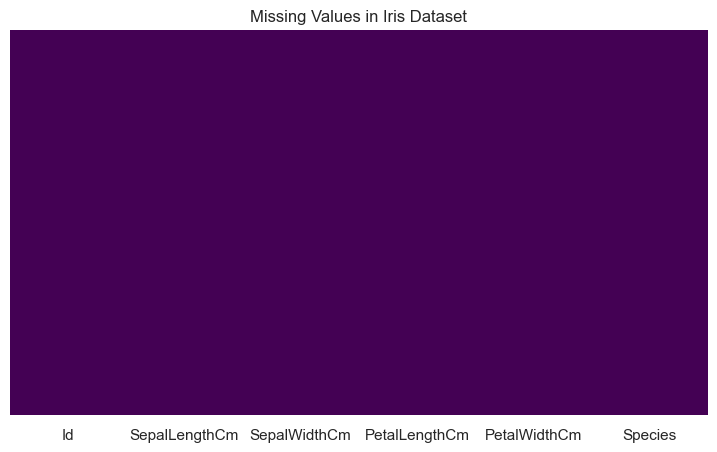

In [7]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in Iris Dataset")
plt.savefig(f"{PLOT_DIR}/missing_values.png", bbox_inches="tight")
plt.show()

In [8]:
print("Total Duplicate Records:", df.duplicated().sum())

display(df[df.duplicated()])

Total Duplicate Records: 0


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species


In [9]:
df_clean = df.copy()

# Standardize column name whitespace
df_clean.columns = df_clean.columns.str.strip()

# Standardize species text whitespace
df_clean["Species"] = df_clean["Species"].str.strip()

# Convert numerical columns to numeric types
numerical_columns = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

for col in numerical_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

print("Basic standardization completed.")

Basic standardization completed.


In [10]:
# Numerical columns: median imputation

for col in numerical_columns:

    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )


# Categorical column: mode imputation

df_clean["Species"] = df_clean["Species"].fillna(
    df_clean["Species"].mode()[0]
)

print("Missing value handling completed.")

Missing value handling completed.


In [11]:
before = len(df_clean)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

after = len(df_clean)

print("Rows Before:", before)
print("Rows After:", after)
print("Rows Removed:", before - after)

Rows Before: 150
Rows After: 150
Rows Removed: 0


In [12]:
print("Negative Measurements:")

print(
    (df_clean[numerical_columns] < 0).sum()
)

print("\nUnique Species:")

print(df_clean["Species"].unique())

print("\nMissing Values After Cleaning:")

print(df_clean.isnull().sum())

Negative Measurements:
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
dtype: int64

Unique Species:
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']

Missing Values After Cleaning:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


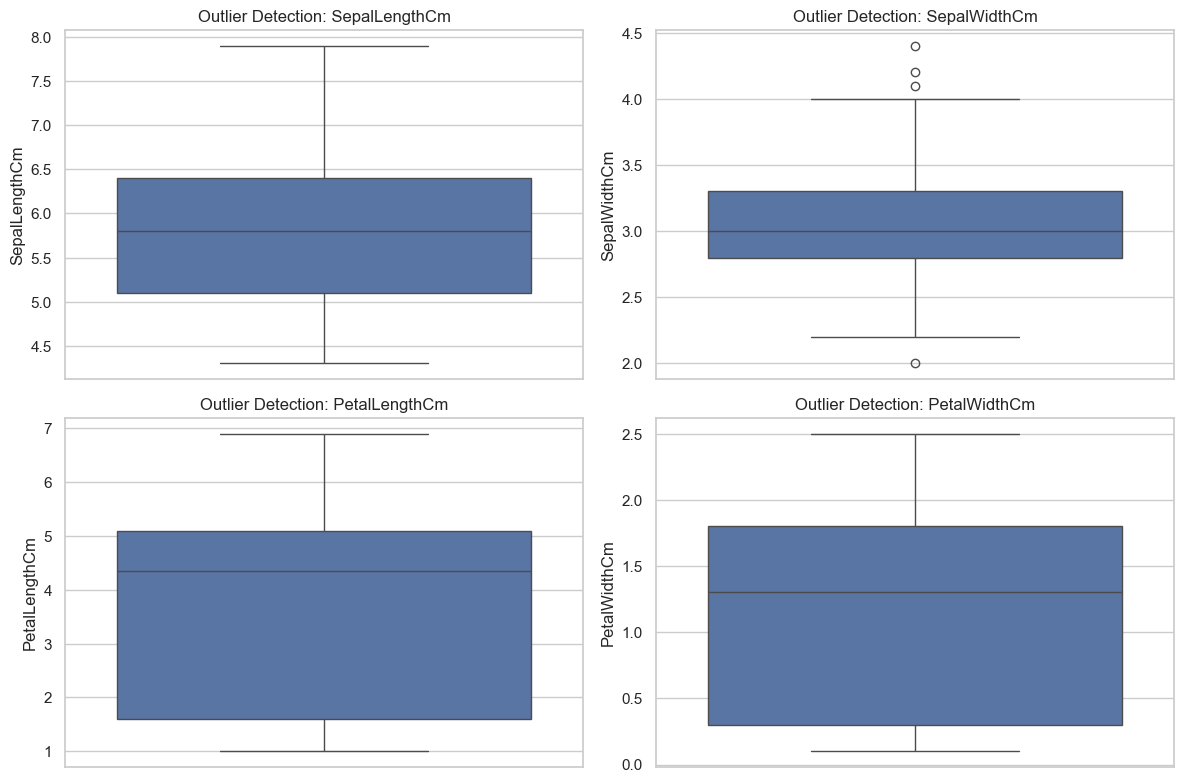

In [13]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(numerical_columns, 1):

    plt.subplot(2, 2, i)

    sns.boxplot(data=df_clean, y=col)

    plt.title(f"Outlier Detection: {col}")

plt.tight_layout()

plt.savefig(
    f"{PLOT_DIR}/outlier_detection.png",
    bbox_inches="tight"
)

plt.show()

In [14]:
outlier_results = []

for col in numerical_columns:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,SepalLengthCm,5.1,6.4,1.3,3.15,8.35,0
1,SepalWidthCm,2.8,3.3,0.5,2.05,4.05,4
2,PetalLengthCm,1.6,5.1,3.5,-3.65,10.35,0
3,PetalWidthCm,0.3,1.8,1.5,-1.95,4.05,0


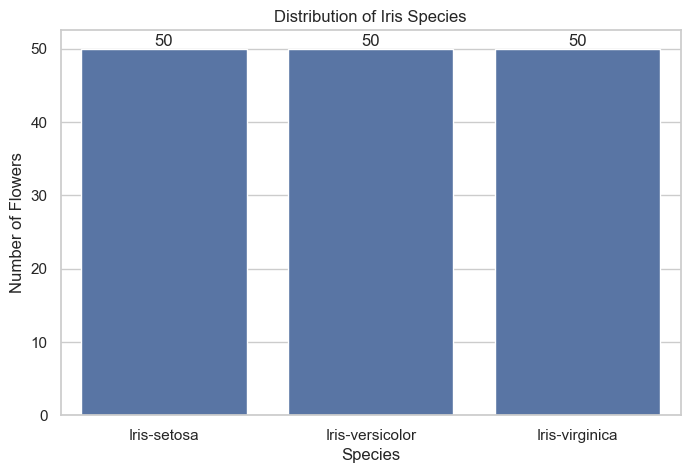

In [15]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x="Species"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")

plt.savefig(
    f"{PLOT_DIR}/species_distribution.png",
    bbox_inches="tight"
)

plt.show()

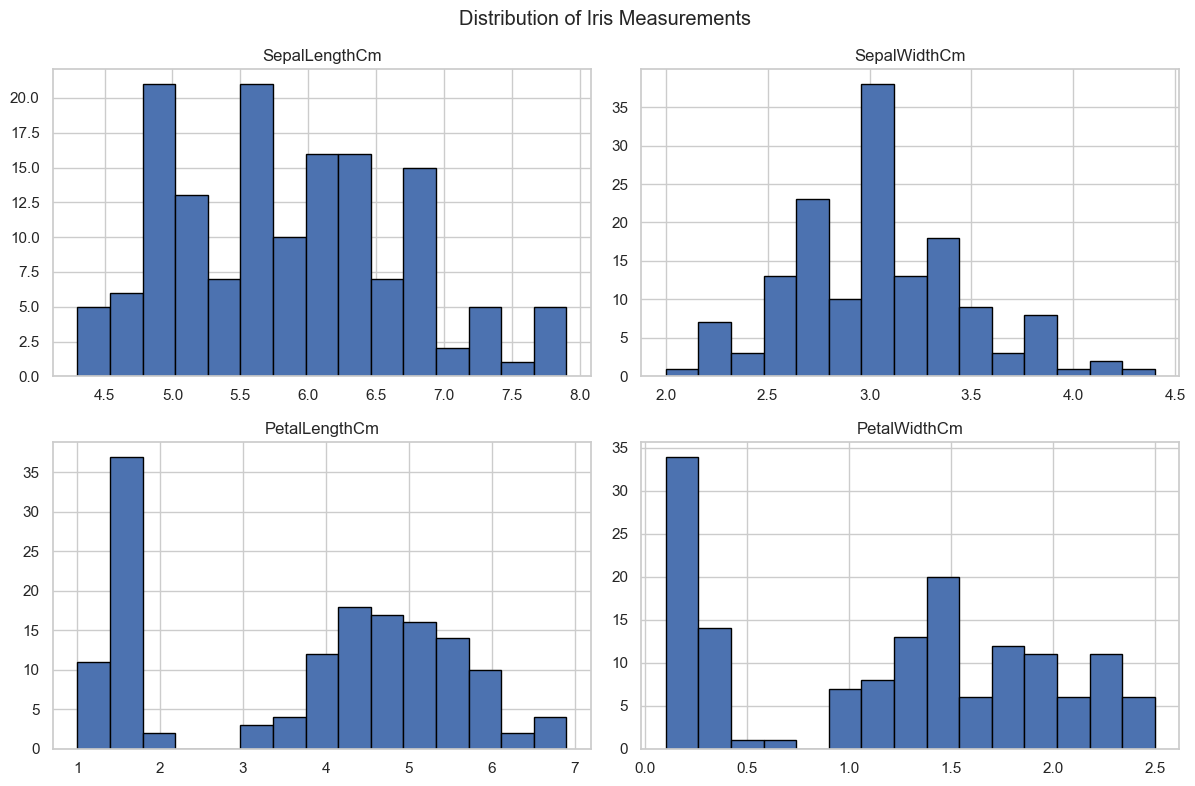

In [16]:
df_clean[numerical_columns].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Measurements")

plt.tight_layout()

plt.savefig(
    f"{PLOT_DIR}/feature_distributions.png",
    bbox_inches="tight"
)

plt.show()

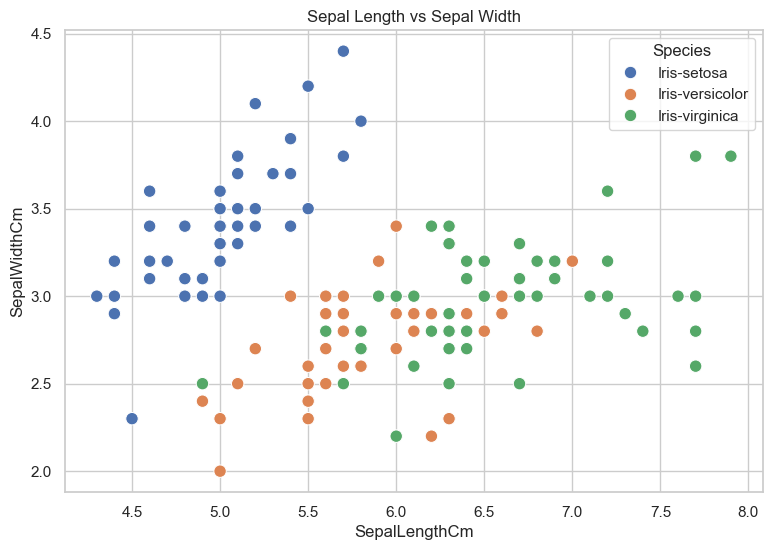

In [17]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_clean,
    x="SepalLengthCm",
    y="SepalWidthCm",
    hue="Species",
    s=80
)

plt.title("Sepal Length vs Sepal Width")

plt.savefig(
    f"{PLOT_DIR}/sepal_comparison.png",
    bbox_inches="tight"
)

plt.show()

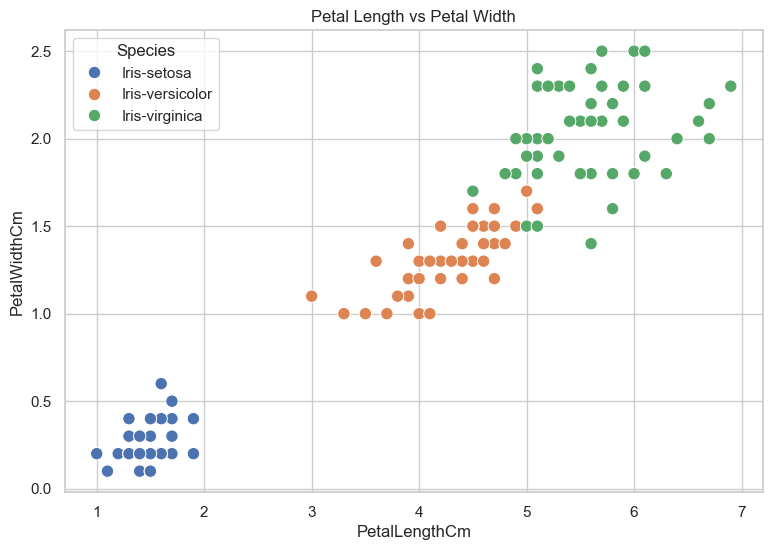

In [18]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_clean,
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Species",
    s=80
)

plt.title("Petal Length vs Petal Width")

plt.savefig(
    f"{PLOT_DIR}/petal_comparison.png",
    bbox_inches="tight"
)

plt.show()

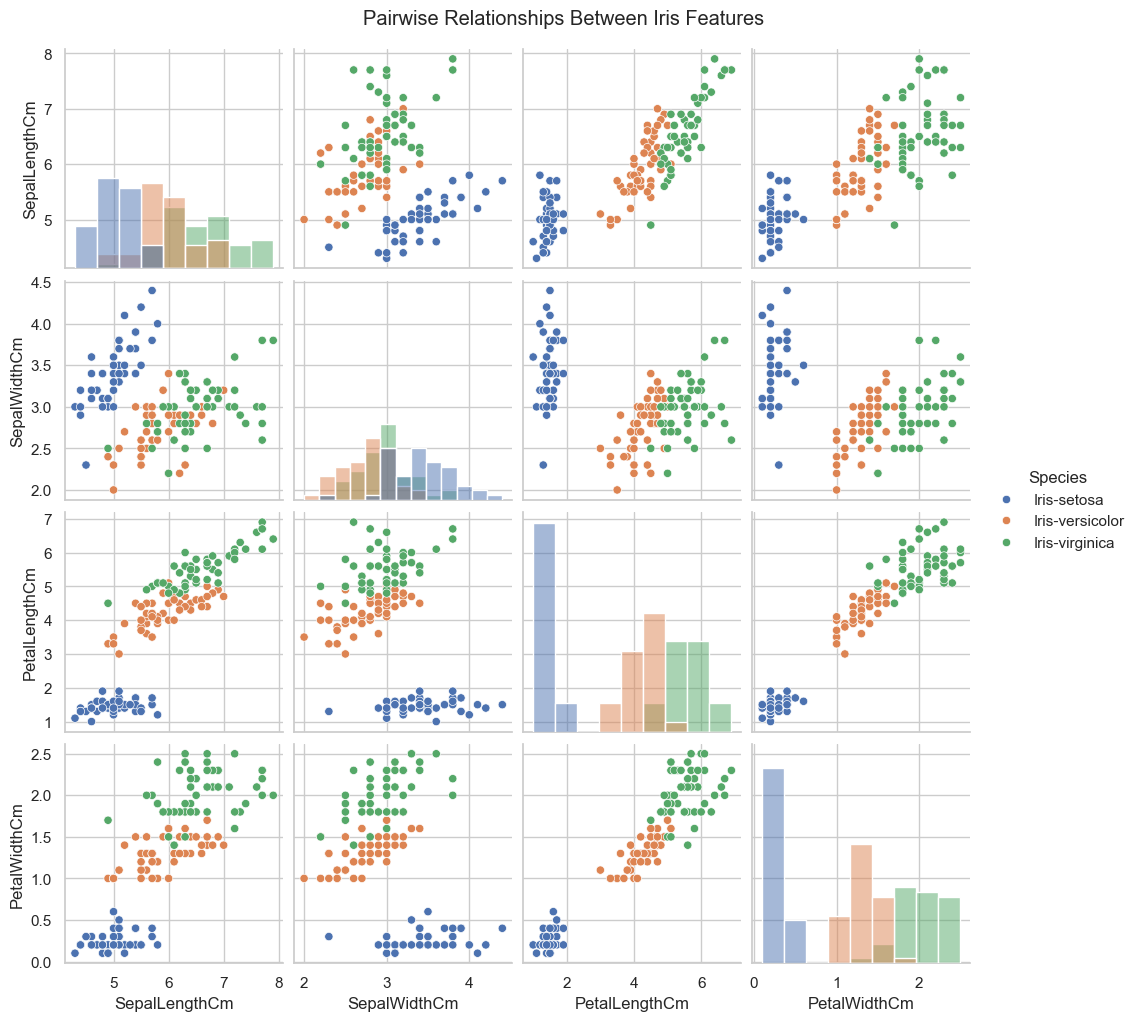

In [19]:
pair_plot = sns.pairplot(
    df_clean,
    vars=numerical_columns,
    hue="Species",
    diag_kind="hist"
)

pair_plot.fig.suptitle(
    "Pairwise Relationships Between Iris Features",
    y=1.02
)

pair_plot.savefig(
    f"{PLOT_DIR}/pairplot.png",
    bbox_inches="tight"
)

plt.show()

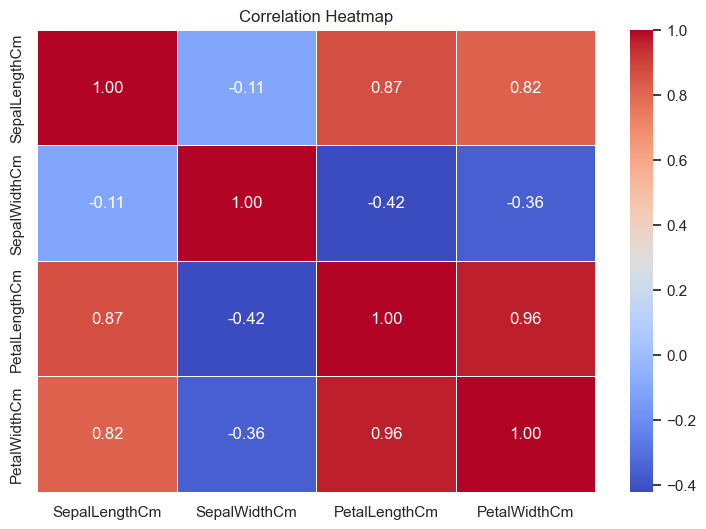

In [20]:
correlation = df_clean[numerical_columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.savefig(
    f"{PLOT_DIR}/correlation_heatmap.png",
    bbox_inches="tight"
)

plt.show()

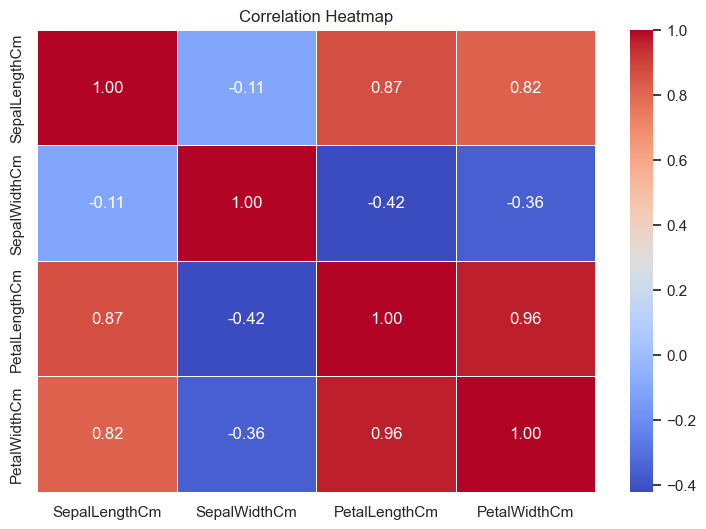

In [21]:
correlation = df_clean[numerical_columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.savefig(
    f"{PLOT_DIR}/correlation_heatmap.png",
    bbox_inches="tight"
)

plt.show()

In [22]:
species_analysis = df_clean.groupby("Species")[
    numerical_columns
].agg(["mean", "median", "std", "min", "max"])

display(species_analysis)

SepalLengthCm                            SepalWidthCm         \
                         mean median       std  min  max         mean median   
Species                                                                        
Iris-setosa             5.006    5.0  0.352490  4.3  5.8        3.418    3.4   
Iris-versicolor         5.936    5.9  0.516171  4.9  7.0        2.770    2.8   
Iris-virginica          6.588    6.5  0.635880  4.9  7.9        2.974    3.0   

                                    PetalLengthCm                             \
                      std  min  max          mean median       std  min  max   
Species                                                                        
Iris-setosa      0.381024  2.3  4.4         1.464   1.50  0.173511  1.0  1.9   
Iris-versicolor  0.313798  2.0  3.4         4.260   4.35  0.469911  3.0  5.1   
Iris-virginica   0.322497  2.2  3.8         5.552   5.55  0.551895  4.5  6.9   

                PetalWidthCm                             
                        mean median       std  min  max  
Species                                                  
Iris-setosa            0.244    0.2  0.107210  0.1  0.6  
Iris-versicolor        1.326    1.3  0.197753  1.0  1.8  
Iris-virginica         2.026    2.0  0.274650  1.4  2.5

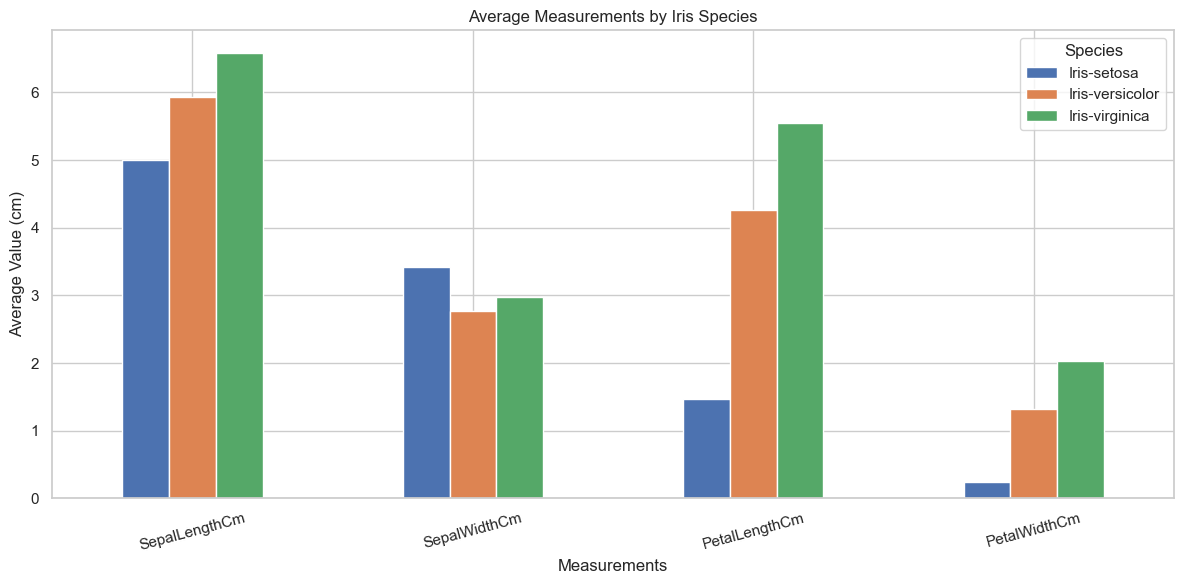

In [23]:
species_mean = df_clean.groupby("Species")[
    numerical_columns
].mean()

species_mean.T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Measurements by Iris Species")
plt.xlabel("Measurements")
plt.ylabel("Average Value (cm)")
plt.xticks(rotation=15)
plt.legend(title="Species")

plt.tight_layout()

plt.savefig(
    f"{PLOT_DIR}/species_comparison.png",
    bbox_inches="tight"
)

plt.show()

In [24]:
df_featured = df_clean.copy()

df_featured["SepalArea"] = (
    df_featured["SepalLengthCm"] *
    df_featured["SepalWidthCm"]
)

df_featured["PetalArea"] = (
    df_featured["PetalLengthCm"] *
    df_featured["PetalWidthCm"]
)

df_featured["PetalToSepalRatio"] = (
    df_featured["PetalLengthCm"] /
    df_featured["SepalLengthCm"]
)

display(df_featured.head())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,SepalArea,PetalArea,PetalToSepalRatio
0,1,5.1,3.5,1.4,0.2,Iris-setosa,17.85,0.28,0.274510
1,2,4.9,3.0,1.4,0.2,Iris-setosa,14.70,0.28,0.285714
2,3,4.7,3.2,1.3,0.2,Iris-setosa,15.04,0.26,0.276596
3,4,4.6,3.1,1.5,0.2,Iris-setosa,14.26,0.30,0.326087
4,5,5.0,3.6,1.4,0.2,Iris-setosa,18.00,0.28,0.280000


In [25]:
new_features = [
    "SepalArea",
    "PetalArea",
    "PetalToSepalRatio"
]

display(
    df_featured.groupby("Species")[new_features].mean()
)

,SepalArea,PetalArea,PetalToSepalRatio
Species,,,
Iris-setosa,17.2088,0.3628,0.293164
Iris-versicolor,16.5262,5.7204,0.717729
Iris-virginica,19.6846,11.2962,0.843749


In [26]:
X = df_featured.drop(
    columns=["Species", "Id"],
    errors="ignore"
)

y = df_featured["Species"]

print("Independent Variables:")
display(X.head())

print("\nDependent Variable:")
display(y.head())

Independent Variables:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,SepalArea,PetalArea,PetalToSepalRatio
0,5.1,3.5,1.4,0.2,17.85,0.28,0.274510
1,4.9,3.0,1.4,0.2,14.70,0.28,0.285714
2,4.7,3.2,1.3,0.2,15.04,0.26,0.276596
3,4.6,3.1,1.5,0.2,14.26,0.30,0.326087
4,5.0,3.6,1.4,0.2,18.00,0.28,0.280000



Dependent Variable:


0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object

In [27]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Species Mapping:")

for index, species in enumerate(label_encoder.classes_):
    print(species, ":", index)

Species Mapping:
Iris-setosa : 0
Iris-versicolor : 1
Iris-virginica : 2


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Data: (120, 7)
Testing Data: (30, 7)
Training Labels: (120,)
Testing Labels: (30,)


In [29]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Standard Scaling Completed.")

print(X_train_scaled[:5])

Standard Scaling Completed.
[[-1.72156775 -0.32483982 -1.34703555 -1.32016847 -1.44087079 -1.16904831
  -1.26872176]
 [-1.12449223 -1.22612948  0.41429037  0.65186742 -1.58828431  0.38317714
   1.25342882]
 [ 1.14439475 -0.55016223  0.58474127  0.25746024  0.37433881  0.18730608
   0.36050634]
 [-1.12449223  0.12580502 -1.29021859 -1.45163753 -0.73848874 -1.19642813
  -1.31939866]
 [-0.40800161 -1.22612948  0.13020555  0.12599118 -1.15471514 -0.13282725
   0.45039479]]


In [30]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Standard Scaling Completed.")

print(X_train_scaled[:5])

Standard Scaling Completed.
[[-1.72156775 -0.32483982 -1.34703555 -1.32016847 -1.44087079 -1.16904831
  -1.26872176]
 [-1.12449223 -1.22612948  0.41429037  0.65186742 -1.58828431  0.38317714
   1.25342882]
 [ 1.14439475 -0.55016223  0.58474127  0.25746024  0.37433881  0.18730608
   0.36050634]
 [-1.12449223  0.12580502 -1.29021859 -1.45163753 -0.73848874 -1.19642813
  -1.31939866]
 [-0.40800161 -1.22612948  0.13020555  0.12599118 -1.15471514 -0.13282725
   0.45039479]]


In [31]:
minmax_scaler = MinMaxScaler()

X_train_minmax = minmax_scaler.fit_transform(X_train)

X_test_minmax = minmax_scaler.transform(X_test)

print("MinMax Scaling Completed.")

print(X_train_minmax[:5])

MinMax Scaling Completed.
[[0.02777778 0.375      0.05172414 0.04166667 0.13786214 0.0107868
  0.11426844]
 [0.16666667 0.20833333 0.5862069  0.66666667 0.11238761 0.4784264
  0.95249611]
 [0.69444444 0.33333333 0.63793103 0.54166667 0.45154845 0.41941624
  0.65573654]
 [0.16666667 0.45833333 0.06896552 0.         0.25924076 0.00253807
  0.09742615]
 [0.33333333 0.20833333 0.5        0.5        0.18731269 0.32296954
  0.68561064]]


In [32]:
print("FINAL DATASET SUMMARY")

print("\nDataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nSpecies Distribution:")
print(df_clean["Species"].value_counts())

print("\nStatistical Summary:")
display(df_clean.describe())

FINAL DATASET SUMMARY

Dataset Shape: (150, 6)

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate Rows:
0

Species Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Statistical Summary:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [33]:
df_clean.to_csv(
    f"{OUTPUT_DIR}/Iris_Cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [34]:
print("Generated Visualization Files:")

for file in os.listdir(PLOT_DIR):
    print(file)

print("\nCleaned Dataset Exists:")

print(
    os.path.exists(
        f"{OUTPUT_DIR}/Iris_Cleaned.csv"
    )
)

Generated Visualization Files:
species_comparison.png
petal_comparison.png
sepal_comparison.png
pairplot.png
missing_values.png
correlation_heatmap.png
species_distribution.png
feature_distributions.png
outlier_detection.png
.ipynb_checkpoints

Cleaned Dataset Exists:
True
